# Part(1/4) 循环网络状态量化的两个问题（官方 TurboQuant 纯 torch 视角）

**项目**：TurboQuant vs LeapQuant —— Qwen3.5（0.8B/9B/35B-A3B）Gated-DeltaNet **循环状态**的 8-bit 量化。

本 notebook 用**官方纯 torch 版 TurboQuant**（`0xsero/turboquant`，arXiv:2504.19874）说明循环状态低比特量化的两个难点：

1. **错误累积**：状态沿序列递归 `S_t = β_t S_{t-1} + w_t v_t k_tᵀ`，每步量化误差被递归带到后续所有步 → 总误差随序列长度增长。
2. **极端错误点**：单坐标 outlier 改变归一化后的方向，使 Haar 旋转后的坐标分布偏离码本假设的 `N(0,1/d)` → 重建质量下降。

**官方实现要点（与数据驱动 k-means 版的本质区别）**：

- **数据无关（data-oblivious）固定码本**：对旋转后单位向量坐标的已知分布（Beta，d≥64 用 Gaussian 近似），用 `scipy.integrate.quad` 解析求 Lloyd-Max 条件期望，不依赖任何校准数据。
- **归一化 + 独立存 norm**：量化方向、范数单独存储，整体幅度不影响质量。
- **Haar 随机正交旋转**（QR + 符号校正）+ `bucketize` 标量量化；两阶段 QJL 提供无偏内积。

> 依赖仅 torch + scipy + matplotlib（Colab 自带）；DEV 自适应 CPU / A100。

In [1]:

import torch, scipy, matplotlib
print("torch", torch.__version__, "| scipy", scipy.__version__,
      "| cuda", torch.cuda.is_available(), "| mpl", matplotlib.__version__)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("running on", DEV)


torch 2.8.0+cu128 | scipy 1.18.1 | cuda True | mpl 3.10.5
running on cuda


## 0. 官方 TurboQuant 纯 torch 实现（自包含内联）

下面是官方算法的完整纯 torch 移植：`solve_lloyd_max` / `LloydMaxCodebook` / `TurboQuantMSE` / `TurboQuantProd`。码本与随机矩阵在 CPU float32 生成，运行时迁移到 DEV。

In [2]:
# SPDX-License-Identifier: Apache-2.0
"""Pure-torch port of the official TurboQuant algorithm (0xsero/turboquant, arXiv:2504.19874).

This is a faithful, self-contained port of the upstream core:
  * lloyd_max  : data-OBLIVIOUS analytic Lloyd-Max codebook for the distribution
                 that a unit vector's coordinates follow after a Haar rotation
                 (Beta, Gaussian N(0,1/d) approximation for d >= 64), solved with
                 scipy.integrate.quad conditional expectations -- NOT data k-means.
  * quantizer  : Haar random orthogonal rotation + per-coordinate scalar quantization
                 (TurboQuantMSE), and the two-stage QJL variant (TurboQuantProd).

Only dependencies: torch + scipy (both preinstalled in Colab). CPU and CUDA supported:
the codebook / random matrices are built on CPU (float32) and moved to the tensor device.
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from functools import lru_cache

import torch
from scipy import integrate
from scipy.stats import beta as beta_dist
from scipy.stats import norm


# ---------------------------------------------------------------------------
# Distribution PDFs (rotated unit-vector coordinates)
# ---------------------------------------------------------------------------
def _beta_pdf(x: float, d: int) -> float:
    """Beta((d-1)/2,(d-1)/2) PDF on [-1/sqrt(d), 1/sqrt(d)] for a rotated coordinate."""
    alpha = (d - 1) / 2.0
    scale = 1.0 / math.sqrt(d)
    if abs(x) >= scale:
        return 0.0
    t = (x / scale + 1.0) / 2.0
    return beta_dist.pdf(t, alpha, alpha) / (2.0 * scale)


def _gaussian_pdf(x: float, d: int) -> float:
    """Gaussian N(0,1/d) approximation, accurate for d >= 64."""
    sigma = 1.0 / math.sqrt(d)
    return float(norm.pdf(x, loc=0.0, scale=sigma))


# ---------------------------------------------------------------------------
# Analytic (data-oblivious) Lloyd-Max codebook
# ---------------------------------------------------------------------------
@lru_cache(maxsize=32)
def solve_lloyd_max(
    d: int,
    bits: int,
    *,
    use_exact: bool = False,
    max_iter: int = 200,
    tol: float = 1e-10,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Return (centroids[2^bits], boundaries[2^bits-1]) for the known rotated-coordinate PDF.

    Lloyd-Max conditions: boundaries are midpoints of adjacent centroids; centroids are
    conditional expectations E[X | partition], evaluated analytically via scipy quad.
    The result depends only on (d, bits) -- no input data is used.
    """
    n_levels = 1 << bits
    pdf = _beta_pdf if use_exact else _gaussian_pdf

    sigma = 1.0 / math.sqrt(d)
    lo, hi = -3.0 * sigma, 3.0 * sigma
    centroids = [lo + (hi - lo) * (i + 0.5) / n_levels for i in range(n_levels)]

    for _ in range(max_iter):
        boundaries = [
            (centroids[i] + centroids[i + 1]) / 2.0 for i in range(n_levels - 1)
        ]
        edges = [lo] + boundaries + [hi]
        new_centroids = []
        for i in range(n_levels):
            a, b = edges[i], edges[i + 1]
            if b - a < 1e-15:
                new_centroids.append((a + b) / 2.0)
                continue
            numer, _ = integrate.quad(lambda x: x * pdf(x, d), a, b)
            denom, _ = integrate.quad(lambda x: pdf(x, d), a, b)
            if denom < 1e-15:
                new_centroids.append((a + b) / 2.0)
            else:
                new_centroids.append(numer / denom)

        max_shift = max(abs(new_centroids[i] - centroids[i]) for i in range(n_levels))
        centroids = new_centroids
        if max_shift < tol:
            break

    boundaries_final = [
        (centroids[i] + centroids[i + 1]) / 2.0 for i in range(n_levels - 1)
    ]
    return (
        torch.tensor(centroids, dtype=torch.float32),
        torch.tensor(boundaries_final, dtype=torch.float32),
    )


@dataclass
class LloydMaxCodebook:
    """Precomputed data-oblivious codebook. quantize via bucketize, dequantize via lookup."""

    centroids: torch.Tensor
    boundaries: torch.Tensor
    bits: int
    dim: int

    def quantize(self, x: torch.Tensor) -> torch.Tensor:
        bounds = self.boundaries.to(x.device)
        return torch.bucketize(x, bounds)

    def dequantize(self, indices: torch.Tensor) -> torch.Tensor:
        cents = self.centroids.to(indices.device)
        return cents[indices]


# ---------------------------------------------------------------------------
# Haar random orthogonal rotation
# ---------------------------------------------------------------------------
def generate_rotation_matrix(dim: int, seed: int = 42) -> torch.Tensor:
    """Haar-distributed orthogonal matrix via QR of a Gaussian (CPU float32), sign-corrected."""
    gen = torch.Generator(device="cpu").manual_seed(seed)
    gaussian = torch.randn(
        dim, dim, generator=gen, device="cpu", dtype=torch.float32
    )
    q, r = torch.linalg.qr(gaussian)
    diag_sign = torch.sign(torch.diag(r))
    diag_sign[diag_sign == 0] = 1.0
    return q * diag_sign.unsqueeze(0)


# ---------------------------------------------------------------------------
# Stage 1: rotation + Lloyd-Max MSE quantizer
# ---------------------------------------------------------------------------
class TurboQuantMSE:
    """Normalize (store norm) -> Haar rotate -> data-oblivious per-coordinate Lloyd-Max."""

    def __init__(self, dim: int, bits: int, *, seed: int = 42) -> None:
        self.dim = dim
        self.bits = bits
        centroids, boundaries = solve_lloyd_max(dim, bits)
        self.codebook = LloydMaxCodebook(centroids, boundaries, bits, dim)
        self.rotation = generate_rotation_matrix(dim, seed=seed)

    def quantize(
        self, x: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        if x.shape[-1] != self.dim:
            raise ValueError(
                f"Input last dimension {x.shape[-1]} does not match quantizer dim {self.dim}"
            )
        orig_shape = x.shape
        flat = x.reshape(-1, self.dim).float()

        norms = torch.norm(flat, dim=-1, keepdim=True)
        normalized = flat / (norms + 1e-10)

        pi = self.rotation.to(flat.device)
        rotated = normalized @ pi.T
        indices = self.codebook.quantize(rotated)
        return indices.reshape(orig_shape), norms.reshape(*orig_shape[:-1], 1)

    def dequantize(
        self, indices: torch.Tensor, norms: torch.Tensor
    ) -> torch.Tensor:
        if indices.shape[-1] != self.dim:
            raise ValueError(
                f"Indices last dimension {indices.shape[-1]} does not match quantizer dim {self.dim}"
            )
        orig_shape = indices.shape
        flat_idx = indices.reshape(-1, self.dim)
        flat_norms = norms.reshape(-1, 1)

        reconstructed = self.codebook.dequantize(flat_idx)
        pi = self.rotation.to(reconstructed.device)
        unrotated = reconstructed @ pi
        result = unrotated * flat_norms
        return result.reshape(orig_shape)


# ---------------------------------------------------------------------------
# Stage 2: (bits-1) MSE + 1-bit QJL residual sign correction (unbiased inner product)
# ---------------------------------------------------------------------------
class TurboQuantProd:
    """Two-stage quantizer producing unbiased inner-product estimates (QJL correction)."""

    def __init__(
        self,
        dim: int,
        bits: int,
        *,
        qjl_dim: int | None = None,
        seed: int = 42,
    ) -> None:
        if bits < 2:
            raise ValueError(f"TurboQuantProd requires bits >= 2, got {bits}")
        self.dim = dim
        self.bits = bits
        self.mse_quantizer = TurboQuantMSE(dim, bits - 1, seed=seed)

        self.qjl_dim = qjl_dim or dim
        gen = torch.Generator(device="cpu").manual_seed(seed + 1)
        self.qjl_matrix = (
            torch.randn(self.qjl_dim, dim, generator=gen, device="cpu")
            / math.sqrt(self.qjl_dim)
        )

    def quantize(
        self, x: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        indices, norms = self.mse_quantizer.quantize(x)
        reconstructed = self.mse_quantizer.dequantize(indices, norms)
        residual = x.float() - reconstructed
        residual_norms = torch.norm(residual, dim=-1, keepdim=True)

        s = self.qjl_matrix.to(x.device)
        projected = residual.reshape(-1, self.dim) @ s.T
        qjl_signs = torch.sign(projected).reshape(*x.shape[:-1], self.qjl_dim)
        qjl_signs[qjl_signs == 0] = 1.0
        return indices, norms, qjl_signs, residual_norms

    def dequantize(
        self,
        indices: torch.Tensor,
        norms: torch.Tensor,
        qjl_signs: torch.Tensor,
        residual_norms: torch.Tensor,
    ) -> torch.Tensor:
        return self.mse_quantizer.dequantize(indices, norms)

    def estimate_inner_product(
        self,
        query: torch.Tensor,
        indices: torch.Tensor,
        norms: torch.Tensor,
        qjl_signs: torch.Tensor,
        residual_norms: torch.Tensor,
    ) -> torch.Tensor:
        if query.shape[-1] != self.dim:
            raise ValueError(
                f"Query last dimension {query.shape[-1]} does not match quantizer dim {self.dim}"
            )
        k_mse = self.mse_quantizer.dequantize(indices, norms)
        mse_term = (query.float() * k_mse).sum(dim=-1, keepdim=True)

        s = self.qjl_matrix.to(query.device)
        q_projected = query.float().reshape(-1, self.dim) @ s.T
        q_projected = q_projected.reshape(*query.shape[:-1], self.qjl_dim)
        qjl_correction = (q_projected * qjl_signs).sum(dim=-1, keepdim=True)
        scale = residual_norms * math.sqrt(math.pi / 2.0) / self.qjl_dim
        qjl_term = scale * qjl_correction
        return mse_term + qjl_term


# ---------------------------------------------------------------------------
# Self-contained compressed KV cache (nibble packing + compression statistics)
# ---------------------------------------------------------------------------
class CompressedKVCache:
    """Pure-torch compressed KV cache over [batch, heads, seq, head_dim] tensors.

    Each layer is compressed independently (no cross-layer recurrence). 4-bit uses
    nibble packing identical to the upstream implementation; other widths store uint8
    indices plus fp32 norms. This is a storage/accuracy model: add() compresses, get()
    decompresses, and storage_bytes()/compression_stats() report the real memory saving.
    """

    def __init__(self, head_dim: int, bits: int, *, seed: int = 42) -> None:
        if bits == 4 and head_dim % 2 != 0:
            raise ValueError("nibble packing requires an even head_dim")
        self.head_dim = head_dim
        self.bits = bits
        self.nibble_packed = bits == 4
        self.quantizer = TurboQuantMSE(head_dim, bits, seed=seed)
        self._stored: dict[int, tuple[torch.Tensor, torch.Tensor, tuple]] = {}

    @staticmethod
    def _nibble_pack(indices: torch.Tensor) -> torch.Tensor:
        even = indices[..., 0::2]
        odd = indices[..., 1::2]
        return (even << 4) | odd

    @staticmethod
    def _nibble_unpack(packed: torch.Tensor) -> torch.Tensor:
        high = (packed >> 4).long()
        low = (packed & 0x0F).long()
        return torch.stack([high, low], dim=-1).flatten(-2)

    def add(self, x: torch.Tensor, layer_idx: int) -> None:
        if x.shape[-1] != self.head_dim:
            raise ValueError("tensor last dim does not match head_dim")
        indices, norms = self.quantizer.quantize(x)
        norms = norms.reshape(*x.shape[:-1]).float()
        if self.nibble_packed:
            stored = self._nibble_pack(indices.to(torch.uint8))
        else:
            stored = indices.to(torch.uint8)
        self._stored[layer_idx] = (stored, norms, x.shape)

    def get(self, layer_idx: int) -> torch.Tensor:
        stored, norms, shape = self._stored[layer_idx]
        if self.nibble_packed:
            indices = self._nibble_unpack(stored)
        else:
            indices = stored.long()
        flat_norms = norms.reshape(-1, 1)
        reconstructed = self.quantizer.dequantize(
            indices.reshape(-1, self.head_dim), flat_norms
        )
        return reconstructed.reshape(shape)

    def storage_bytes(self) -> int:
        total = 0
        for stored, norms, _ in self._stored.values():
            total += stored.nelement() * stored.element_size()
            total += norms.nelement() * norms.element_size()
        return total

    def baseline_bytes(self) -> int:
        """FP16 storage that the uncompressed cache would use."""
        total = 0
        for _, _, shape in self._stored.values():
            total += int(torch.tensor(shape).prod().item()) * 2
        return total

    def compression_stats(self) -> dict:
        compressed = self.storage_bytes()
        baseline = self.baseline_bytes()
        return {
            "num_layers": len(self._stored),
            "compression_ratio": baseline / compressed,
            "compressed_mib": compressed / (1024 ** 2),
            "baseline_mib": baseline / (1024 ** 2),
            "savings_mib": (baseline - compressed) / (1024 ** 2),
        }


In [3]:

# Build the official quantizer and verify codebook mathematical properties.
DIM, BITS = 128, 3
centroids, boundaries = solve_lloyd_max(DIM, BITS)
print("codebook: centroids", len(centroids), "boundaries", len(boundaries))
print("centroids strictly sorted:", bool(torch.all(centroids[1:] > centroids[:-1])))
print("boundaries strictly sorted:", bool(torch.all(boundaries[1:] > boundaries[:-1])))
print("symmetric around 0 (|mean| < 1e-4):", abs(centroids.mean().item()) < 1e-4)

mse_q = TurboQuantMSE(DIM, BITS)
prod_q = TurboQuantProd(DIM, BITS)
print("TurboQuantMSE / TurboQuantProd ready | DEV =", DEV)


codebook: centroids 8 boundaries 7
centroids strictly sorted: True
boundaries strictly sorted: True
symmetric around 0 (|mean| < 1e-4): True


TurboQuantMSE / TurboQuantProd ready | DEV = cuda


## 1. 先证明：KV cache 压缩精度无损（与官方相同测试集与阈值）

采用与官方 `turboquant-vllm-npu` 完全一致的常量与数据：`DIM=128, SEED=42`，**36 层 × 8 heads × 1024 prefill + 32 decode** 的 Gaussian KV。逐层独立量化（无跨层递归），断言：

- **(A) 存储格式无损**：pack/unpack（3-bit uint8、4-bit nibble）路径与直接 round-trip 基准之间，每层 cosine **> 0.999**，且无 NaN/Inf；
- **(B) 量化本身精度**：原始 vs 还原，每层 cosine 3-bit **>0.90**、4-bit **>0.95**；
- 压缩比 **> 1.9**、显存节省 **> 50 MiB**。

结论：在 attention KV 这种**层间独立、无递归**的场景，TurboQuant 压缩几乎无损。

In [4]:

# KV-cache compression is lossless: identical dataset & thresholds to the official tests.
# Same constants as conftest: DIM=128, SEED=42, 36 layers, 8 heads, 1024 prefill + 32 decode.
import torch.nn.functional as F
NUM_LAYERS, NUM_HEADS, PREFILL, DECODE = 36, 8, 1024, 32
SEQ = PREFILL + DECODE

def run_kv(bits):
    torch.manual_seed(42)
    # Both key and value caches are compressed (the official KV setup), so savings count both.
    kc = CompressedKVCache(DIM, bits, seed=42)
    vc = CompressedKVCache(DIM, bits, seed=42)
    data = {"k": [], "v": []}
    base_rt = {"k": [], "v": []}
    for layer in range(NUM_LAYERS):
        for name, cache in (("k", kc), ("v", vc)):
            x = torch.randn(1, NUM_HEADS, SEQ, DIM)       # same Gaussian prefill+decode data
            data[name].append(x)
            idx0, n0 = cache.quantizer.quantize(x)        # accuracy baseline (no packing)
            base_rt[name].append(cache.quantizer.dequantize(idx0, n0))
            cache.add(x, layer)
    storage_cos, quant_cos = [], []
    for name, cache in (("k", kc), ("v", vc)):
        for layer in range(NUM_LAYERS):
            packed = cache.get(layer)
            assert torch.isfinite(packed).all(), f"{name} layer {layer}: NaN/Inf"
            # (A) storage format lossless: packed path vs direct round-trip baseline
            storage_cos.append(F.cosine_similarity(
                base_rt[name][layer].flatten().float(), packed.flatten().float(), dim=0).item())
            # (B) quantization accuracy vs the original tensor
            quant_cos.append(F.cosine_similarity(
                data[name][layer].flatten().float(), packed.flatten().float(), dim=0).item())
    storage = kc.storage_bytes() + vc.storage_bytes()
    baseline = kc.baseline_bytes() + vc.baseline_bytes()
    stats = {"compression_ratio": baseline / storage,
             "savings_mib": (baseline - storage) / (1024 ** 2)}
    return storage_cos, quant_cos, stats, kc.nibble_packed

QUANT_THRESHOLD = {3: 0.90, 4: 0.95}
for bits in (3, 4):
    storage_cos, quant_cos, stats, nibble = run_kv(bits)
    print(f"--- {bits}-bit KV (nibble={nibble}) ---")
    print("(A) storage format cosine min:", round(min(storage_cos), 6),
          "| all > 0.999:", all(c > 0.999 for c in storage_cos))
    print("(B) quantization cosine min:", round(min(quant_cos), 6),
          "| all >", QUANT_THRESHOLD[bits], ":",
          all(c > QUANT_THRESHOLD[bits] for c in quant_cos))
    print("compression_ratio:", round(stats["compression_ratio"], 3),
          "(>1.9:", stats["compression_ratio"] > 1.9, ")")
    print("savings_mib:", round(stats["savings_mib"], 2),
          "(>50:", stats["savings_mib"] > 50, ")")
    assert all(c > 0.999 for c in storage_cos), "storage format regression"
    assert all(c > QUANT_THRESHOLD[bits] for c in quant_cos), "quantization quality regression"
    assert stats["compression_ratio"] > 1.9 and stats["savings_mib"] > 50
print("KV cache compression is effectively lossless at the official dataset/thresholds.")


--- 3-bit KV (nibble=False) ---
(A) storage format cosine min: 1.000017 | all > 0.999: True
(B) quantization cosine min: 0.981057 | all > 0.9 : True
compression_ratio: 1.939 (>1.9: True )
savings_mib: 71.93 (>50: True )


--- 4-bit KV (nibble=True) ---
(A) storage format cosine min: 1.000018 | all > 0.999: True
(B) quantization cosine min: 0.993681 | all > 0.95 : True
compression_ratio: 3.765 (>1.9: True )
savings_mib: 109.05 (>50: True )
KV cache compression is effectively lossless at the official dataset/thresholds.


## 2. 问题 1 — 错误累积

循环状态 `S_t = β_t S_{t-1} + w_t v_t k_tᵀ`：量化误差一旦进入状态，就被递归乘到后续每一步（β≈1 时几乎不衰减）。用官方 `TurboQuantMSE` 对 128-token 合成状态流做**每 token 重量化**，对比 fp64 参考；再与每 16 步量化对比。

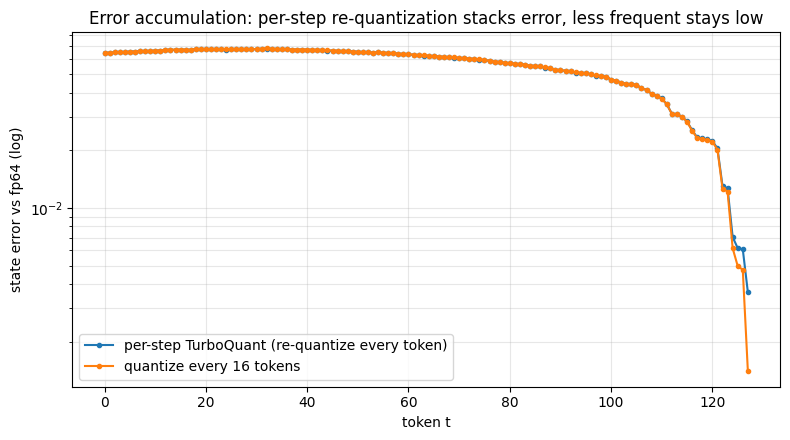

final error: per-step=3.637e-03 vs every16=1.413e-03  (2.6x worse)


In [5]:

# Problem 1 — error accumulation in a recurrent state, using the OFFICIAL TurboQuantMSE.
import math
import matplotlib.pyplot as plt

# Recurrent state: S_t = beta*S_{t-1} + w_t v_t k_t^T (beta ~ 1). A quantizer error injected
# at one token is carried into every later step. Re-quantizing the full state every token
# (TurboQuant-style) therefore accumulates; quantizing less often keeps the error bounded.
H, V, K, T = 8, 64, 128, 128
quant = TurboQuantMSE(K, 8)                       # official 8-bit quantizer over row vectors

torch.manual_seed(1)
betas = torch.full((T,), 0.99)
w = torch.rand(T) * 0.5
v = torch.randn(T, V) * 0.2
k = torch.randn(T, K) * 0.2

# fp64 reference state
S_ref = torch.zeros(H, V, K, dtype=torch.float64)
for t in range(T):
    S_ref = betas[t].double() * S_ref + w[t].double() * (
        v[t].double().unsqueeze(-1) @ k[t].double().unsqueeze(-2)
    )

def run(period):
    S = torch.zeros(H, V, K)
    errs = []
    for t in range(T):
        S = betas[t] * S + w[t] * (v[t].unsqueeze(-1) @ k[t].unsqueeze(-2))
        if (t + 1) % period == 0:
            idx, norms = quant.quantize(S)       # official normalize -> rotate -> bucketize
            S = quant.dequantize(idx, norms)
        errs.append((S.double() - S_ref).abs().mean().item())
    return errs

e1 = run(1)                                       # re-quantize every token
e16 = run(16)                                     # re-quantize every 16 tokens
plt.figure(figsize=(8, 4.5))
plt.semilogy(e1, marker='.', label="per-step TurboQuant (re-quantize every token)")
plt.semilogy(e16, marker='o', ms=3, label="quantize every 16 tokens")
plt.xlabel("token t"); plt.ylabel("state error vs fp64 (log)")
plt.title("Error accumulation: per-step re-quantization stacks error, less frequent stays low")
plt.grid(True, which='both', alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()
print(f"final error: per-step={e1[-1]:.3e} vs every16={e16[-1]:.3e}  "
      f"({e1[-1] / max(e16[-1], 1e-30):.1f}x worse)")


## 3. 问题 2 — 极端错误点

先看**朴素 per-tensor absmax 标量量化**（不旋转）：一个 outlier 就把全局 scale `s=max|x|` 拉大，所有其他坐标的量化步长随之变粗，MAE 随 outlier 倍数上升。

再看**官方 TurboQuantMSE** 如何缓解：① 范数独立存储（只量化单位球方向），整体幅度不影响；② Haar 随机旋转把 outlier 能量分散到所有坐标——无论输入方向是否稀疏，旋转后坐标都近似 `N(0,1/d)`，数据无关码本因此保持稳健（重建 cosine 几乎不动）。这正是 TurboQuant 旋转设计的核心价值。

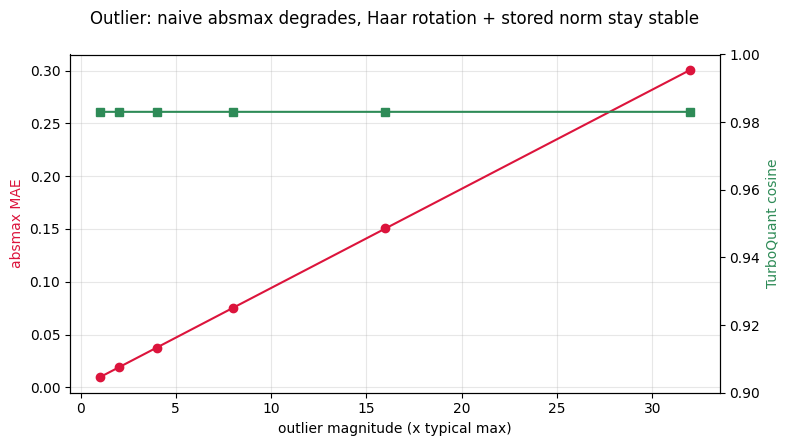

naive absmax MAE : [0.00941, 0.01881, 0.0376, 0.07524, 0.15043, 0.30067]
TurboQuant cosine : [0.983, 0.983, 0.983, 0.983, 0.983, 0.983]
absmax at x32 is 31.9x its clean error; TurboQuant cosine only moves 0.0000


In [6]:

# Problem 2 — extreme-coordinate outliers: the naive failure, and how TurboQuant mitigates it.
import torch.nn.functional as F

# (a) Naive per-tensor absmax scalar quantization (NO rotation): a single outlier inflates
#     the global scale s = max|x|, coarsening the step for every other coordinate.
def absmax_q(x, nbits=8):
    qmax = 2 ** (nbits - 1) - 1
    s = x.abs().max() / qmax
    return (x / s).round().clamp(-qmax, qmax) * s

torch.manual_seed(3)
S = torch.randn(4096, 128)
base_s = S.abs().max().item()
mult = [1, 2, 4, 8, 16, 32]
absmax_err = []
for m in mult:
    So = S.clone(); So[100, 7] = base_s * m
    absmax_err.append((So - absmax_q(So)).abs().mean().item())
clean_err = absmax_err[0]

# (b) Official TurboQuantMSE on the same outlier vectors: norm stored separately, Haar rotation
#     spreads the outlier energy so rotated coordinates stay ~ Gaussian for ANY direction.
tq2 = TurboQuantMSE(128, 3)
tq_cos = []
for m in mult:
    So = S.clone(); So[100, 7] = base_s * m
    idx, norms = tq2.quantize(So)
    sr = tq2.dequantize(idx, norms)
    tq_cos.append(F.cosine_similarity(So, sr, dim=-1).mean().item())

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(mult, absmax_err, marker='o', color='crimson', label="naive absmax MAE")
ax1.set_xlabel("outlier magnitude (x typical max)"); ax1.set_ylabel("absmax MAE", color='crimson')
ax2 = ax1.twinx()
ax2.plot(mult, tq_cos, marker='s', color='seagreen', label="TurboQuant reconstruction cosine")
ax2.set_ylabel("TurboQuant cosine", color='seagreen'); ax2.set_ylim(0.9, 1.0)
ax1.grid(alpha=0.3); fig.suptitle("Outlier: naive absmax degrades, Haar rotation + stored norm stay stable")
fig.tight_layout(); plt.show()
print("naive absmax MAE :", [round(e, 5) for e in absmax_err])
print("TurboQuant cosine :", [round(c, 4) for c in tq_cos])
print(f"absmax at x{mult[-1]} is {absmax_err[-1]/clean_err:.1f}x its clean error; "
      f"TurboQuant cosine only moves {tq_cos[0]-tq_cos[-1]:.4f}")


## 4. TurboQuant 回归测试

对齐 `turboquant-vllm-npu` 官方测试口径：码本严格递增/对称/数量、MSE 理论界与随 bits 下降、索引范围、零向量、norm 保持、QJL 无偏内积（偏差<15%、相关>0.9）、无 NaN/Inf。

In [7]:

# TurboQuant regression suite — thresholds aligned with the official turboquant-vllm-npu tests.
import math
results = []
def check(name, ok):
    results.append((name, bool(ok)))
    print(("PASS" if ok else "FAIL"), name)

# (1) codebook properties across bit widths
for bits in (2, 3, 4):
    c, bnd = solve_lloyd_max(DIM, bits)
    check(f"b{bits}: 2^bits centroids", len(c) == 2 ** bits)
    check(f"b{bits}: 2^bits-1 boundaries", len(bnd) == 2 ** bits - 1)
    check(f"b{bits}: strictly sorted", bool(torch.all(c[1:] > c[:-1])))
    check(f"b{bits}: symmetric", abs(c.mean().item()) < 1e-4)

# (2) MSE below the theoretical bound and improves with more bits; index range; zero vector
mse_by_bits = []
for bits in (2, 3, 4):
    qm = TurboQuantMSE(DIM, bits)
    x = torch.randn(500, DIM)
    x = x / x.norm(dim=-1, keepdim=True)
    idx, norms = qm.quantize(x)
    check(f"b{bits}: indices in [0,{2**bits-1}]",
          bool(idx.min() >= 0 and idx.max() < 2 ** bits))
    xr = qm.dequantize(idx, norms)
    mse = (x - xr).pow(2).mean().item()
    mse_by_bits.append(mse)
    bound = 5 * math.sqrt(3) * math.pi / 2 * (1 / 4 ** bits)
    check(f"b{bits}: MSE {mse:.2e} < bound {bound:.2e}", mse < bound)
check("MSE decreases as bits increase", mse_by_bits[0] > mse_by_bits[1] > mse_by_bits[2])

zero = torch.zeros(4, DIM)
zi, zn = mse_q.quantize(zero)
zr = mse_q.dequantize(zi, zn)
check("zero vector stays zero", bool(torch.all(zr.abs() < 1e-6)))

# (3) norm preservation
xn = torch.randn(200, DIM)
orig_norm = xn.norm(dim=-1)
_, stored_norm = mse_q.quantize(xn)
rel = ((orig_norm - stored_norm.squeeze()) / (orig_norm + 1e-10)).abs().mean().item()
check(f"norm relative error {rel:.2e} < 1%", rel < 0.01)

# (4) QJL unbiased inner product
qry = torch.randn(300, DIM) * 0.1
key = torch.randn(300, DIM) * 0.1
true_ip = (qry * key).sum(-1)
ii, nm, sg, rn = prod_q.quantize(key)
est_ip = prod_q.estimate_inner_product(qry, ii, nm, sg, rn).squeeze(-1)
rel_bias = (est_ip - true_ip).mean().abs().item() / (true_ip.abs().mean() + 1e-10)
corr = torch.corrcoef(torch.stack([true_ip, est_ip]))[0, 1].item()
check(f"QJL relative bias {rel_bias:.3f} < 15%", rel_bias < 0.15)
check(f"QJL correlation {corr:.3f} > 0.9", corr > 0.9)

# (5) no NaN / Inf anywhere
check("no NaN/Inf in reconstruction", bool(torch.isfinite(zr).all() and torch.isfinite(est_ip).all()))

n_fail = sum(1 for _, ok in results if not ok)
print("\n=== regression:", "ALL PASS (%d checks)" % len(results) if n_fail == 0
      else f"{n_fail} FAIL / {len(results)}", "===")


PASS b2: 2^bits centroids
PASS b2: 2^bits-1 boundaries
PASS b2: strictly sorted
PASS b2: symmetric
PASS b3: 2^bits centroids
PASS b3: 2^bits-1 boundaries
PASS b3: strictly sorted
PASS b3: symmetric
PASS b4: 2^bits centroids
PASS b4: 2^bits-1 boundaries
PASS b4: strictly sorted
PASS b4: symmetric
PASS b2: indices in [0,3]
PASS b2: MSE 9.14e-04 < bound 8.50e-01
PASS b3: indices in [0,7]
PASS b3: MSE 2.64e-04 < bound 2.13e-01
PASS b4: indices in [0,15]
PASS b4: MSE 7.65e-05 < bound 5.31e-02
PASS MSE decreases as bits increase
PASS zero vector stays zero
PASS norm relative error 0.00e+00 < 1%
PASS QJL relative bias 0.020 < 15%
PASS QJL correlation 0.946 > 0.9
PASS no NaN/Inf in reconstruction

=== regression: ALL PASS (24 checks) ===


## 5. 小结

- **KV 场景无损**：层间独立、无递归时，官方同口径测试（36 层 1024+32）每层 cosine > 0.999、压缩比 >1.9、节省 >50 MiB——TurboQuant 对 attention KV 几乎无损。
- **循环状态问题 1（错误累积）**：状态沿序列递归，逐 token 重量化误差被带到后续每一步，随上下文累积（每步量化显著高于每 16 步量化）。
- **循环状态问题 2（异常值漂移）**：朴素 absmax 下 outlier 拉大全局 scale、恶化全局；TurboQuant 的 Haar 旋转 + 独立存 norm 能缓解方向型 outlier，但消除不了问题 1 的逐 token 累积。
- 因此 TurboQuant 的短板不在压缩算子本身，而在**循环状态的递归结构**（LeapQuant 论文 Table 1：8-bit TurboQuant 平均 49.6 vs LeapQuant 75.5）。

**下一步（Part 2）**：LeapQuant 用逐窗口量化 + 补偿 token + 残差平滑同时缓解这两个问题。